# Propagation Analysis

In [1]:
%load_ext autoreload
%autoreload 2
%matplotlib widget

In [ ]:
import concurrent.futures
from itertools import product
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from scipy.fft import irfft, rfft, ifftshift, ifft, fft
from scipy.signal import ShortTimeFFT, coherence, welch
from scipy.signal.windows import hann
from tqdm import tqdm
from tritonoa.modeling.at.kraken import run_kraken
from tritonoa.modeling.physics import propagate_signal
from tritonoa.signal import waveforms
from tritonoa.signal.util import get_freqs_from_band

from rodeo import model as mdl, plotting, utils

plt.style.use(Path("config/jasa_fig_style.mplstyle"))

SAVEPATH = Path.cwd() / "results"


def plot_orig_and_dispersed(t, x, y):
    fig, axs = plt.subplots(nrows=2)
    ax = axs[0]
    ax.plot(t, x)
    ax.set_xlim(t[0], t[-1])
    ax.set_xlabel("Time (s)")
    ax.set_ylabel("Pressure (Pa)")
    ax = axs[1]
    ax.plot(t, y)
    ax.set_xlim(t[0], t[-1])
    ax.set_xlabel("Reduced time (s)")
    ax.set_ylabel("Pressure (Pa)")
    fig.tight_layout()
    return fig

## Load SSP

In [ ]:
ctd_file = Path("data/ctd/sfw_leg2_2023-07-23/CTD_cast_south_fork_07_23_2023_data.txt")
# Downcast to the deepest sample, one sample per depth, sorted by depth.
ctd_df = utils.load_ssp(ctd_file, min_depth=1.0)

plot_kwargs = {
    "Temperature": {"label": "Temperature", "color": "black"},
    "Salinity": {"label": "Salinity", "color": "black"},
    "Speed of sound": {"label": "Speed of sound", "color": "black"},
}
fig = plotting.plot_ctd_profiles(ctd_df, **plot_kwargs)

## Create environment model w/ SSP data

In [ ]:
base_environment = mdl.construct_environment()
layerdata = base_environment["layerdata"]
z = ctd_df["Depth"].to_numpy()
c_p = ctd_df["Speed of sound"].to_numpy()
z = np.append(z, layerdata[0]["z"].max())
c_p = np.append(c_p, c_p[-1])
z = np.insert(z, 0, 0.0)
c_p = np.insert(c_p, 0, layerdata[0]["c_p"])

new_layerdata = [
    {"z": z, "c_p": c_p},
    layerdata[1],
]
base_environment.update({"layerdata": new_layerdata})

## Point Source Analysis

### Mode Function

5.0


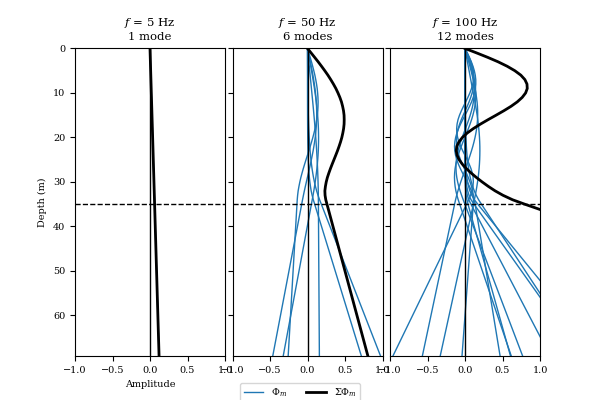

In [41]:
environment = base_environment.copy()
print(environment["src_z"])
freqs = [5.0, 50.0, 100.0]
zgrid = np.arange(0, 70, 1)
environment.update({"rec_z": zgrid})
phis = []
for freq in freqs:
    model = run_kraken(environment | {"freq": freq}, keep_files=True)
    phis.append(model.modes.phi_rec)

fig = plotting.plot_mode_function(environment, phis, freqs, zgrid)
# fig.savefig(SAVEPATH / "mode_function.png", dpi=600, bbox_inches="tight", facecolor="w")
plt.show()

### Predicted pressure fields at VLA1 & VLA2

Station VLA 1
Station VLA 2
Complete.


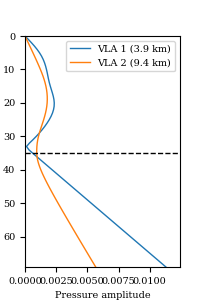

In [6]:
freqs = np.arange(40, 200, 1)
src_depth = 20.0

pressures = []
for station, dist in {"VLA 1": 3.9, "VLA 2": 9.4}.items():
    print(f"Station {station}")
    pressure = np.zeros((len(freqs), len(zgrid)), dtype=complex)
    for i, freq in enumerate(freqs):
        model = run_kraken(
            environment | {"freq": freq, "src_z": src_depth, "rec_r": dist}
        )
        pressure[i] = model.modes.p.squeeze()
    pressure = pressure.sum(axis=0)
    pressures.append(pressure)
print("Complete.")

fig = plotting.plot_pressure_fields(
    pressures, zgrid, 35.0, labels=["VLA 1 (3.9 km)", "VLA 2 (9.4 km)"]
)
# fig.savefig(SAVEPATH / "pressure_fields.png", dpi=600, bbox_inches="tight", facecolor="w")
plt.show()

### Pulse Propagation

#### Define environment

In [ ]:
from soundscape.config import load_site
from soundscape.events import load_events, source_range

SITE = load_site(Path("config/sites/southfork.toml"))


def station_range(event: str, station: str) -> float:
    """Distance (m) from the event's pile to the sensor."""
    pile = {e.name: e for e in load_events(SITE)}[event]
    sensor = {s.name: s for s in SITE.sensors}[station]
    return source_range(pile, sensor)


event = "A10-B"
station = "VLA2"
range_m = station_range(event, station)
print(f"Range to {station}: {range_m:.1f} m")

#### Define source functions

In [ ]:
def generate_source_function(
    signal_duration: float,
    pulse_duration: float,
    fs: float,
    fc: float = 100.0,
    snr_db: float = np.inf,
):
    pulse = waveforms.generate_gaussian_pulse(pulse_duration, fc, fs, sigma=0.005)

    t = np.arange(0, signal_duration, 1 / fs)
    num_samples = t.size
    x = np.concatenate([pulse, np.zeros(num_samples - pulse.size)])

    signal_power = np.mean(pulse**2)
    noise_rms = np.sqrt(signal_power / (10 ** (snr_db / 10)))
    noise = np.random.normal(0, 1, num_samples) * noise_rms
    return t, x + noise


signal_duration = 0.5
pulse_duration = 0.25
fs = 4096
num_samples = int(signal_duration * fs)
starting_fc = 475.0
snr_db = 30.0

sym_index = num_samples // 2

flim = (0, 1000)

num_signals = 4
signals = np.zeros((num_signals, num_samples))
for i in range(num_signals):
    t, signals[i] = generate_source_function(
        signal_duration, pulse_duration, fs, fc=starting_fc + 4 * i, snr_db=snr_db
    )

S_mat = np.abs(rfft(signals, axis=1))
f = np.fft.rfftfreq(signals.shape[1], d=1 / fs)

plt.figure()
plt.subplot(211)
[plt.plot(t, s) for s in signals]
plt.xlabel("Time (s)")
plt.ylabel("Amplitude")
plt.title("Source signals - Time domain")

plt.subplot(212)
[plt.plot(f, S) for S in S_mat]
plt.xlim(flim)
plt.xlabel("Frequency (Hz)")
plt.ylabel("Amplitude")
plt.title("Source signals - Frequency domain")

plt.tight_layout()
plt.show()

print(num_samples)

#### Create Green's function

In [ ]:
def compute_greens_function(freq):
    model = run_kraken(environment | {"freq": freq})
    return model.modes.p.squeeze()

fl = 40
fu = fs
N = signals.shape[1]

# Define frequencies
freqs, _ = get_freqs_from_band(N, [fl, fu], fs=fs)

# Define the environment
environment = mdl.construct_environment()
environment.update({"rec_r": range_m / 1e3})

# Expected travel time:
c_max = 1500.0
t_offset = environment["rec_r"] * 1e3 / c_max

# Compute Green's Function in parallel
with concurrent.futures.ThreadPoolExecutor() as executor:
    p_f = list(tqdm(executor.map(compute_greens_function, freqs), total=len(freqs)))
p_partial = np.array(p_f)
padding = len(f) - p_partial.shape[0]
p = np.concatenate([np.zeros(padding, dtype=complex), p_partial])

In [ ]:
print((fl, fu), freqs.min(), freqs.max())

In [ ]:
H = np.abs(p)

h = ifft(p * np.conj(p), n=num_samples)

plt.figure()

plt.subplot(211)
plt.plot(t, np.real(h))
plt.xlabel("Time (s)")
plt.title("Channel impulse response")

plt.subplot(212)
plt.plot(f, H)
plt.xlabel("Frequency (Hz)")
plt.title("Channel frequency response")
plt.xlim(flim)

plt.tight_layout()
plt.show()

#### Propagate signals through channel

In [16]:
received_signals = propagate_signal(signals, p, f, t_offset, nfft=num_samples)
Y_mat = np.abs(rfft(received_signals, axis=1))
f = np.fft.rfftfreq(received_signals.shape[1], d=1/fs)

plt.figure()

plt.subplot(211)
[plt.plot(t, y) for y in received_signals]
plt.xlabel("Time (s)")
plt.ylabel("Amplitude")
plt.title("Received signals - Time domain")

plt.subplot(212)
[plt.plot(f, Y) for Y in Y_mat]
plt.xlabel("Frequency (Hz)")
plt.ylabel("Amplitude")
plt.title("Source signals - Frequency domain")
plt.xlim(flim)

plt.tight_layout()
plt.show()

ValueError: operands could not be broadcast together with shapes (4,2048) (1025,) 

In [ ]:
nperseg = signals.shape[1] // 8
noverlap = int(0.75 * nperseg)

coherence_kwargs = {
    "fs": fs,
    "nperseg": nperseg,
    "noverlap": noverlap,
    "nfft": num_samples,
}

f_coh, Cxy_src = coherence(
    np.tile(signals[0], (num_signals, 1)), signals, **coherence_kwargs
)
f_coh, Cxy_rec = coherence(
    np.tile(received_signals[0], (num_signals, 1)), received_signals, **coherence_kwargs
)
c_src = irfft(Cxy_src * np.conj(Cxy_src))
c_rec = irfft(Cxy_rec * np.conj(Cxy_rec))

delta_Cxy = Cxy_rec - Cxy_src
delta_c = c_rec - c_src

labels = [f"$C_{{1,{i + 1}}}$" for i in range(num_signals)]


plt.figure(figsize=(10, 5))
xlim_time = (0, 0.02)
xlim_freq = flim

plt.subplot(231)
for i, label in enumerate(labels):
    plt.plot(t[:sym_index], c_src[i][:sym_index], label=label)
    plt.xlim(xlim_time)
plt.xlabel("Time (s)")

plt.subplot(232)
for i, label in enumerate(labels):
    plt.plot(t[:sym_index], c_rec[i][:sym_index], label=label)
    plt.xlim(xlim_time)
plt.xlabel("Time (s)")

plt.subplot(233)
for i, label in enumerate(labels):
    plt.plot(t[:sym_index], delta_c[i][:sym_index], label=label)
    plt.xlim(xlim_time)
plt.xlabel("Time (s)")

plt.subplot(234)
for i, label in enumerate(labels):
    plt.plot(f_coh, Cxy_src[i], label=label)
# plt.xlim(0, fs / 2)
plt.xlim(xlim_freq)
plt.ylim(-0.01, 1.01)
plt.grid(which="both")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Coherence")
plt.title("Coherence between source signals")

plt.subplot(235)
for i, label in enumerate(labels):
    plt.plot(f_coh, Cxy_rec[i], label=label)
# plt.xlim(0, fs / 2)
plt.xlim(xlim_freq)
plt.ylim(-0.01, 1.01)
plt.grid()
plt.xlabel("Frequency (Hz)")
plt.ylabel("Coherence")
plt.title("Coherence between received signals")

plt.subplot(236)
for i, label in enumerate(labels):
    plt.plot(f_coh, delta_Cxy[i], label=label)
# plt.xlim(0, fs / 2)
plt.xlim(xlim_freq)
plt.xlabel("Frequency (Hz)")
plt.ylabel("Difference")
plt.title("Difference (rec - src) in coherence")
plt.legend(loc="upper left", bbox_to_anchor=(1, 1))

plt.tight_layout()
plt.show()

In [ ]:
S1 = rfft(signals[0])
S2 = rfft(signals[-1])

S12 = np.conj(S1) * S2
YY = S12 * np.abs(H)**2


s12 = ifft(S12, n=num_samples)
yy = ifft(YY, n=num_samples)

plt.figure(figsize=(10, 5))
plt.subplot(221)
plt.plot(f, np.real(S12)[0:sym_index + 1], label="Real part")
plt.plot(f, np.imag(S12)[0:sym_index + 1], label="Imaginary part")
plt.plot(f, np.abs(S12)[0:sym_index + 1], label="Magnitude")
plt.xlim(flim)
plt.xlabel("Frequency (Hz)")
plt.legend()
plt.title("$S_1^* S_2$")

plt.subplot(222)
plt.plot(f, np.real(YY), label="Real part")
plt.plot(f, np.imag(YY), label="Imaginary part")
plt.plot(f, np.abs(YY), label="Magnitude")
plt.xlim(flim)
plt.xlabel("Frequency (Hz)")
plt.title("$S_1^* S_2 \\vert H \\vert^2$")

plt.subplot(223)
plt.plot(t, np.real(s12), label="Real part")
plt.plot(t, np.imag(s12), label="Imaginary part")
plt.plot(t, np.abs(s12), label="Magnitude")
plt.xlim(0, 0.5)
plt.xlabel("Time (s)")
plt.title("$s_{12}$")

plt.subplot(224)
plt.plot(t, np.real(yy), label="Real part")
plt.plot(t, np.imag(yy), label="Imaginary part")
plt.plot(t, np.abs(yy), label="Magnitude")
plt.xlim(0, 0.5)
plt.xlabel("Time (s)")
plt.title("$y_{12}$")

plt.tight_layout()
plt.show()



In [ ]:
# Write a function for the e-folding time



s12_norm = s12 / np.abs(s12).max()
yy_norm = yy / np.abs(yy).max()

plt.figure()
plt.subplot(211)
plt.plot(t, s12)
plt.xlim(0, 0.25)

plt.subplot(212)
plt.plot(t, yy)
plt.xlim(0, 0.25)

plt.tight_layout()
plt.show()

## Idealized Line Source Analysis

### Predicted pressure fields at VLA1 & VLA2

In [ ]:
# freqs = np.arange(40, 200, 1)
# source_depths = np.arange(0, 45, 0.5)

# pressures = []
# for station, dist in {"VLA 1": 3.9, "VLA 2": 9.4}.items():
#     print(f"Station {station}")
#     pressure = np.zeros((len(freqs), len(source_depths), len(zgrid)), dtype=complex)
#     for (i, freq), (j, src_depth) in product(
#         enumerate(freqs), enumerate(source_depths)
#     ):
#         model = run_kraken(
#             environment | {"freq": freq, "src_z": src_depth, "rec_r": dist}
#         )
#         pressure[i, j] = model.modes.p.squeeze()
#     pressure = pressure.sum(axis=(0, 1))
#     pressures.append(pressure)
# print("Complete.")

# fig = plotting.plot_pressure_fields(
#     pressures, zgrid, 35.0, labels=["VLA 1 (3.9 km)", "VLA 2 (9.4 km)"]
# )
# # fig.savefig(SAVEPATH / "pressure_fields.png", dpi=600, bbox_inches="tight", facecolor="w")
# plt.show()

In [ ]:
# M = 512
# pcoverlap = 0.9
# win = hann(M)
# SFT = ShortTimeFFT(win, hop=int((1 - pcoverlap) * M), mfft=8 * M, fs=fs, scale_to="psd")
# Sx = SFT.stft(x)
# Sy = SFT.stft(y)
# Sx = 10 * np.log10(np.abs(Sx) ** 2)
# Sy = 10 * np.log10(np.abs(Sy) ** 2)

# t = SFT.t(len(x))

In [ ]:
# ylim = (10, 1000)

# fig, axs = plt.subplots(ncols=2, figsize=(6, 3), gridspec_kw={"wspace": 0.07})
# ax = axs[0]
# # im = ax.imshow(Sx, aspect="auto", origin="lower", extent=SFT.extent(len(x)), interpolation="none")
# im = ax.pcolormesh(t, SFT.f, Sx[0:-1, 0:-1], shading="flat")
# ax.set_yscale("log")
# ax.set_ylim(ylim)
# ax.set_xlabel("Reduced time (s)")
# ax.set_ylabel("Frequency (Hz)")

# ax = axs[1]
# im = ax.pcolormesh(t, SFT.f, Sy[0:-1, 0:-1], shading="flat")
# ax.set_yscale("log")
# ax.set_ylim(ylim)
# ax.set_yticklabels([])

# plt.show()

# # TODO: Figure out how to adjust extent more easily

In [ ]:
# f, Pxx = welch(x, fs=fs, nperseg=4096, noverlap=2048)
# _, Pyy = welch(y, fs=fs, nperseg=4096, noverlap=2048)

# Pxx = 10 * np.log10(Pxx / np.max(np.abs(Pxx)))
# Pyy = 10 * np.log10(Pyy / np.max(np.abs(Pyy)))

# fig = plt.figure()
# plt.plot(f, Pxx, c="tab:blue", label="Original")
# plt.plot(f, Pyy, c="tab:orange", label="Dispersed")
# plt.xscale("log")
# plt.grid(True)
# plt.xlim(10, 10000)
# plt.xlabel("Frequency (Hz)")
# plt.ylabel("Power spectral density (dB/Hz)")
# plt.legend()
# plt.show()